# Model Training

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from imblearn.combine import SMOTETomek

import time
from datetime import datetime

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.linear_model import LogisticRegression
from mord import LogisticAT
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

import optuna

from sklearn.base import BaseEstimator, clone

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, roc_curve, auc

import sys
from pathlib import Path

In [ ]:
# Add the project root directory to the Python path
project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.feature.group_rare_cat import RareCategoryGrouper
from src.feature.target_encoding import GeoLevel3TargetEncoder

In [ ]:
train_df = pd.read_csv('../data/processed/train_data_processed.csv')
test_value = pd.read_csv('../data/processed/test_values_processed.csv')

train_df.head()

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,...,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use_other,damage_grade,height_area_ratio,has_secondary_use_manufacture,has_secondary_use_public,has_secondary_use_business
0,6,487,12198,2,30.0,t,r,n,f,q,...,0,0,v,1,0,3,0.833333,0,0,0
1,8,900,2812,2,10.0,o,r,n,x,q,...,0,0,v,1,0,2,0.875000,0,0,0
2,21,363,8973,2,10.0,t,r,n,f,x,...,0,0,v,1,0,3,1.000000,0,0,0
3,22,418,10694,2,10.0,t,r,n,f,x,...,0,0,v,1,0,2,0.833333,0,0,0
4,11,131,1488,3,30.0,t,r,n,f,x,...,0,0,v,1,0,3,1.125000,0,0,0


### Train-Test Split

In [ ]:
# Separate data and target
y = train_df['damage_grade']
X = train_df.drop(['damage_grade'], axis=1)

# Split the data
X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)  # Keep the class distribution of the target variable consistent

X_train

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
185461,716310,21,935,5965,3,20,6,6,t,r,...,0,0,0,0,0,0,0,0,0,0
190537,283080,3,1229,1099,2,20,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
232781,690774,21,1219,2705,3,45,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
213004,904803,20,158,2452,2,10,7,5,t,w,...,0,0,0,0,0,0,0,0,0,0
177786,991971,9,670,5977,2,0,9,6,t,i,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99791,819626,8,1184,830,1,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
150155,865223,4,144,5751,2,0,8,4,t,r,...,0,0,0,0,0,0,0,0,0,0
112797,363536,27,548,1119,3,20,19,7,t,r,...,0,0,0,0,0,0,0,0,0,0
225588,402196,17,1030,606,2,15,8,8,t,r,...,0,0,0,0,0,0,0,0,0,0


### Pipeline

In [ ]:
# One-hot encoding columns
ohe_cols = ['geo_level_1_id', 'land_surface_condition', 'foundation_type', 'roof_type',
       'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

# Numerical columns
num_cols = ['count_floors_pre_eq', 'age', 'count_families', 'height_area_ratio']

# Numerical columns preprocessing pipeline
num_pipeline = Pipeline([
    ('imputing', SimpleImputer(missing_values=np.nan, strategy='median')),
    ('log', FunctionTransformer(np.log1p)),  # Log transformation
    ('standardisation', StandardScaler())
])

# Preprocessing pipeline
ct1 = ColumnTransformer(transformers=[
    ('one-hot', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore', dtype=int), ohe_cols),  # Drop first
    ('num cols manipulation', num_pipeline, num_cols)
    ],
    remainder='passthrough',
    n_jobs=-1
)

# Full preprocessing pipeline
preprocessing_pipeline = Pipeline([
    (
        'rare categories',
        RareCategoryGrouper(
            columns=ohe_cols
        )
    ),
    (
        'target encoding',
        GeoLevel3TargetEncoder(min_count=10)
    ),
    (
        'column transformations',
        ct1
    )
])

Give it a try on a **Logistic Regression Model**.

In [ ]:
# Logistic Regression Pipeline
pipeline_lr = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('smotetomek', SMOTETomek(random_state=42)),   # Oversampling using SMOTETomek
    ('LogisticRegression', LogisticRegression(class_weight='balanced', max_iter=1000))
])

# Training
pipeline_lr.fit(X_train, y_train)

# Predicting
y_pred_lr = pipeline_lr.predict(X_validation)

# Micro F1 Score
micro_f1_lr = f1_score(y_validation, y_pred_lr, average='micro')
print('Micro-averaged F1:', micro_f1_lr)

# Evaluate the model
print('Confusion Matrix:\n', confusion_matrix(y_validation, y_pred_lr))
print('\nClassification Report:\n', classification_report(y_validation, y_pred_lr))

Micro-averaged F1: 0.7249285316858848
Confusion Matrix:
 [[ 4151   757   117]
 [ 3831 20740  5081]
 [  503  4048 12893]]

Classification Report:
               precision    recall  f1-score   support

           1       0.49      0.83      0.61      5025
           2       0.81      0.70      0.75     29652
           3       0.71      0.74      0.73     17444

    accuracy                           0.72     52121
   macro avg       0.67      0.75      0.70     52121
weighted avg       0.75      0.72      0.73     52121



In [ ]:
# Check unique value
np.unique(y_pred_lr)

array([1, 2, 3], dtype=int64)

### Model Training and Hyperparameter Tuning

The target variable, `damage_grade`, is an **ordinal categorical** feature. As a result, an ordinal regression algorithm, `LogisticAT` from the *mord* library, is applied.  
In addition, the paper [A Simple Approach to Ordinal Classification](https://www.researchgate.net/publication/226877154_A_Simple_Approach_to_Ordinal_Classification) introduces a method that enables standard classification algorithms to exploit the ordering information in class attributes.  
>The method converts the original ordinal class problem into a series of binary class problems that encode the ordering of the original classes.

Based on this approach, several standard classification models are trained and fine-tuned. The best-performing model is then converted into an ordinal classifier using the implementation provided in  [Ordinal Classification (tune_sklearn, skorch)](https://www.kaggle.com/code/jayahn0104/ordinal-classification-tune-sklearn-skorch#2.-Model-Selection), and is further tuned to evaluate potential score improvement. Finally, the trained models are used to make predictions on the test set, and the results are submitted to [DrivenData](https://www.drivendata.org/competitions/57/nepal-earthquake/submissions/) to determine which model achieves the highest leaderboard score.  

#### LogisticAT

In [ ]:
# LogisticAT pipeline
pipeline_lat = Pipeline([
    ('preprocessing', ct1),
    ('smotetomek', SMOTETomek(random_state=42)),
    ('lat', LogisticAT()) # No class_weight in LogisticAT()
])

# Parameter grid
grid_lat = {
    'smotetomek': [SMOTETomek(random_state=42), 'passthrough'],  # With or without oversampling
    'lat__alpha': [0, 0.001, 0.01, 0.1, 1, 10]
}

# Define the GridSearchCV
gcv_lat = GridSearchCV(
    pipeline_lat,
    grid_lat,
    scoring='f1_micro',
    cv=5,
    n_jobs=-1,
    verbose=2
)

# Start time
start_time = time.time()

# Fit the model
gcv_lat.fit(X_train,y_train)

# Calculate training time
training_time = (time.time() - start_time) / 60

# Get the best parameters and score
print('Best Params:', gcv_lat.best_params_)
print('Best Score:', gcv_lat.best_score_)

# Print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'lat__alpha': 1, 'smotetomek': 'passthrough'}
Best Score: 0.7370443207981582

Training Time: 30.79 min


##### Evaluation

In [ ]:
# Evaluate the model with the tuned hyperparameters

pipeline_lat = Pipeline([
    ('preprocessing', ct1),
    ('lat', LogisticAT(alpha = 1))
])

# Fit the model
pipeline_lat.fit(X_train, y_train)

# Prediction
y_pred_train_lat = pipeline_lat.predict(X_train)
y_pred_valid_lat = pipeline_lat.predict(X_validation)

# Micro-averaged F1
micro_f1_train_lat = f1_score(y_train, y_pred_train_lat, average='micro')
micro_f1_valid_lat = f1_score(y_validation, y_pred_valid_lat, average='micro')

print('Micro-averaged F1 (train):', micro_f1_train_lat)
print('Micro-averaged F1 (validation):', micro_f1_valid_lat)

# Evaluate the model
confusion_matrix_lat = confusion_matrix(y_validation, y_pred_valid_lat)
print('\nConfusion Matrix:\n', confusion_matrix_lat)
print('\nClassification Report:\n', classification_report(y_validation, y_pred_valid_lat))

Micro-averaged F1 (train): 0.7371642363775902
Micro-averaged F1 (validation): 0.7374762571708141

Confusion Matrix:
 [[ 2005  2974    46]
 [  911 25327  3414]
 [   30  6308 11106]]

Classification Report:
               precision    recall  f1-score   support

           1       0.68      0.40      0.50      5025
           2       0.73      0.85      0.79     29652
           3       0.76      0.64      0.69     17444

    accuracy                           0.74     52121
   macro avg       0.72      0.63      0.66     52121
weighted avg       0.74      0.74      0.73     52121



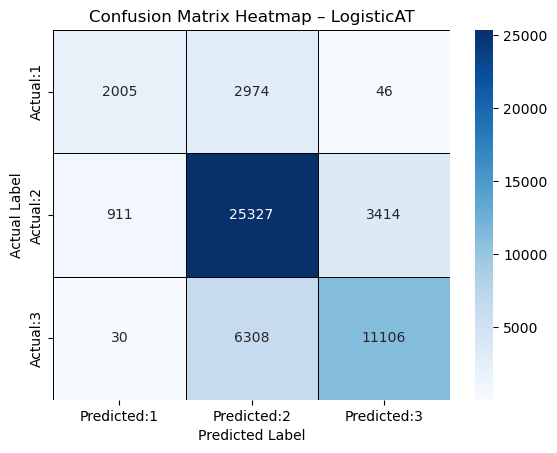

In [ ]:
# Confusion Matrix Heatmap

confusion_matrix_df_lat = pd.DataFrame(
    data=confusion_matrix_lat,
    columns=['Predicted:1', 'Predicted:2', 'Predicted:3'],
    index=['Actual:1', 'Actual:2', 'Actual:3']
)

sns.heatmap(confusion_matrix_df_lat, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap – LogisticAT')
plt.show()

- Micro-averaged F1 (validation): 0.7375.
- The model performed best on class 2, and worst on class 1.
- Class 1 and 3 were frequently misclassified as class 2.

##### Prediction

In [ ]:
# Make predictions on the test set

test_predict_lat = pipeline_lat.predict(test_value1)
test_predict_lat

array([3, 2, 2, ..., 2, 2, 2])

In [ ]:
# Submission

my_submission_lat = pd.DataFrame(data=test_predict_lat,
                             columns=submission_format.columns,
                             index=submission_format.index)
my_submission_lat.head()

,damage_grade
building_id,
300051,3
99355,2
890251,2
745817,1
421793,3


In [ ]:
# Save the predictions into a csv file

# Get the current datetime
now = datetime.now().strftime('%Y%m%d_%H%M%S')

# File name with the current datetime
filename = f'submission_{now}.csv'

# Save the predictions into a csv file
my_submission_lat.reset_index().to_csv('submission/' + filename, index=False)

Submission score: 0.7213

#### LinearSVC

In [ ]:
# LinearSVC pipeline
pipeline_lsvc = Pipeline([
    ('preprocessing', ct1),
    ('smotetomek', SMOTETomek(random_state=42)),
    ('lsvc', LinearSVC(class_weight='balanced'))
])

grid_lsvc = {
    'smotetomek': [SMOTETomek(random_state=42), 'passthrough']
}

gcv_lsvc = GridSearchCV(
    pipeline_lsvc, 
    grid_lsvc,
    scoring='f1_micro',
    cv=5,
    n_jobs=-1,
    verbose=2
)

# start time
start_time = time.time()

gcv_lsvc.fit(X_train,y_train)

# calculate training time
training_time = (time.time() - start_time) / 60

print('Best Params:', gcv_lsvc.best_params_)
print('Best Score:', gcv_lsvc.best_score_)

# print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Params: {'smotetomek': 'passthrough'}
Best Score: 0.7354806216423637

Training Time: 8.51 min


In [ ]:
pipeline_lsvc = Pipeline([
    ('preprocessing', ct1),
    ('lsvc', LinearSVC(class_weight='balanced'))
])

grid_lsvc = {
    'lsvc__C': [0.0001, 0.001, 0.01, 0.1, 1, 10],  # Tune the regularisation parameter first
    'lsvc__penalty': ['l1', 'l2']
}

gcv_lsvc = GridSearchCV(
    pipeline_lsvc, 
    grid_lsvc,
    scoring='f1_micro',
    cv=5,
    n_jobs=-1,
    verbose=2
)

# start time
start_time = time.time()

gcv_lsvc.fit(X_train,y_train)

# calculate training time
training_time = (time.time() - start_time) / 60

print('Best Params:', gcv_lsvc.best_params_)
print('Best Score:', gcv_lsvc.best_score_)

# print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'lsvc__C': 0.001, 'lsvc__penalty': 'l2'}
Best Score: 0.7360178434382195

Training Time: 3.61 min


In [ ]:
pipeline_lsvc = Pipeline([
    ('preprocessing', ct1),
    ('lsvc', LinearSVC(
        C=0.001,
        penalty='l2',
        class_weight='balanced'))
])

grid_lsvc = {
    'lsvc__multi_class': ['ovr', 'crammer_singer'],
    'lsvc__loss': ['hinge', 'squared_hinge']
}

gcv_lsvc = GridSearchCV(
    pipeline_lsvc, 
    grid_lsvc,
    scoring='f1_micro',
    cv=5,
    n_jobs=-1,
    verbose=2
)

# start time
start_time = time.time()

gcv_lsvc.fit(X_train,y_train)

# calculate training time
training_time = (time.time() - start_time) / 60

print(gcv_lsvc.best_params_)
print(gcv_lsvc.best_score_)

# print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 4 candidates, totalling 20 fits
{'lsvc__loss': 'squared_hinge', 'lsvc__multi_class': 'ovr'}
0.7360178434382195

Training Time: 0.23 min


##### Evaluation

In [ ]:
# Evaluate the model with the tuned hyperparameters

pipeline_lsvc.set_params(
    lsvc__C = 0.001,
    lsvc__penalty = 'l2',
    lsvc__loss = 'squared_hinge',
    lsvc__multi_class ='ovr'
)

pipeline_lsvc.fit(X_train, y_train)
y_pred_train_lsvc = pipeline_lsvc.predict(X_train)
y_pred_valid_lsvc = pipeline_lsvc.predict(X_validation)

micro_f1_train_lsvc = f1_score(y_train, y_pred_train_lsvc, average='micro')
micro_f1_valid_lsvc = f1_score(y_validation, y_pred_valid_lsvc, average='micro')

print('Micro-averaged F1 (train):', micro_f1_train_lsvc)
print('Micro-averaged F1 (validation):', micro_f1_valid_lsvc)

confusion_matrix_lsvc = confusion_matrix(y_validation, y_pred_valid_lsvc)
print('\nConfusion Matrix:\n', confusion_matrix_lsvc)
print('\nClassification Report:\n', classification_report(y_validation, y_pred_valid_lsvc))

Micro-averaged F1 (train): 0.7363871834228704
Micro-averaged F1 (validation): 0.7419658103259723

Confusion Matrix:
 [[ 3686  1228   111]
 [ 2686 22976  3990]
 [  361  5073 12010]]

Classification Report:
               precision    recall  f1-score   support

           1       0.55      0.73      0.63      5025
           2       0.78      0.77      0.78     29652
           3       0.75      0.69      0.72     17444

    accuracy                           0.74     52121
   macro avg       0.69      0.73      0.71     52121
weighted avg       0.75      0.74      0.74     52121



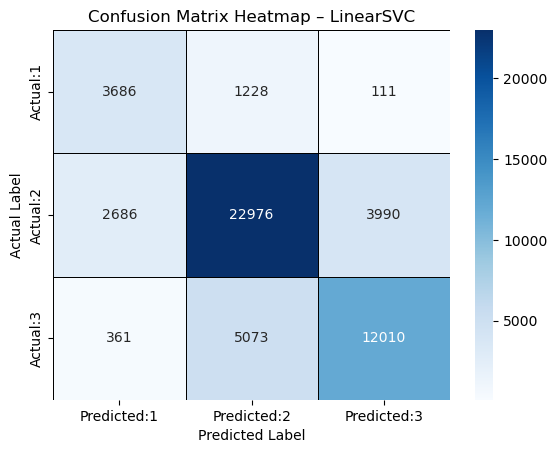

In [ ]:
# Confusion Matrix Heatmap

confusion_matrix_df_lsvc = pd.DataFrame(
    data=confusion_matrix_lsvc,
    columns=['Predicted:1', 'Predicted:2', 'Predicted:3'],
    index=['Actual:1', 'Actual:2', 'Actual:3']
)

sns.heatmap(confusion_matrix_df_lsvc, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap – LinearSVC')
plt.show()

- Micro-averaged F1 (validation): 0.7420, slightly higher than `LogisticAT`.
- The model performed best on class 2, and worst on class 1.
- Classes 1 and 3 were frequently misclassified as class 2, but the number of misclassifications was slightly fewer compared to `LogisticAT`.

##### Prediction

In [ ]:
# Make predictions on the test set

test_predict = pipeline_lsvc.predict(test_value1)
test_predict

array([3, 2, 2, ..., 2, 2, 1], dtype=int64)

In [ ]:
my_submission = pd.DataFrame(data=test_predict,
                             columns=submission_format.columns,
                             index=submission_format.index)
my_submission.head()

,damage_grade
building_id,
300051,3
99355,2
890251,2
745817,1
421793,3


In [ ]:
# Save the predictions into a csv file

now = datetime.now().strftime('%Y%m%d_%H%M%S')

filename = f'submission_{now}.csv'

my_submission.reset_index().to_csv('submission/' + filename, index=False)

# Print confirmation
print(f"Submission file saved successfully as 'submission/{filename}'")

Submission file saved successfully as 'submission/submission_20250519_165449.csv'


Submission score: 0.7176

#### Random Forest

##### Hyperparameter Tuning

In [ ]:
# Grid Search

# RandomForestClassifier pipeline
pipeline_rfc = Pipeline([
    ('preprocessing', ct1),
    ('smotetomek', SMOTETomek(random_state=42)),
    ('rfc', RandomForestClassifier(class_weight='balanced'))
])

grid_rfc = {
    'smotetomek': [SMOTETomek(random_state=42), 'passthrough']  # With or without oversampling
}

gcv_rfc = GridSearchCV(
    pipeline_rfc, 
    grid_rfc, 
    scoring='f1_micro', 
    cv=5,
    n_jobs=8,
    verbose=2
)

# start time
start_time = time.time()

gcv_rfc.fit(X_train,y_train)

# calculate training time
training_time = (time.time() - start_time) / 60

print('Best Params:', gcv_rfc.best_params_)
print('Best Score:', gcv_rfc.best_score_)

# print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Params: {'smotetomek': 'passthrough'}
Best Score: 0.7362768610897927

Training Time: 7.58 min


In [ ]:
# Bayesian Optimisation

# Define the objective function
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 500, 1300)
    max_depth = trial.suggest_int('max_depth', 10, 80)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.2, 0.3, 0.4, 0.5, 0.7])
    criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
    max_samples = trial.suggest_float('max_samples', 0.1, 1.0)

    # RandomForestClassifier pipeline
    pipeline_rfc = Pipeline([
        ('preprocessing', ct1),
        ('rfc', RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            criterion=criterion,
            max_samples=max_samples,
            class_weight='balanced',
            n_jobs=3
        ))
    ])

    # CV
    f1_score = cross_val_score(pipeline_rfc, X_train, y_train, cv=3, scoring='f1_micro', n_jobs=3).mean()
    return f1_score

# Study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=150)

best_trial_rfc = study.best_trial

best_score_rfc = best_trial_rfc.value
best_params_rfc = best_trial_rfc.params

# Print the best params and the score
print('Best Score:', best_score_rfc)
print('Best Params:', best_params_rfc)

[I 2025-05-19 17:04:04,254] A new study created in memory with name: no-name-31da40eb-40cf-4552-974e-b68d18ad9c20
[I 2025-05-19 17:05:51,445] Trial 0 finished with value: 0.7314562475369089 and parameters: {'n_estimators': 878, 'max_depth': 61, 'min_samples_split': 12, 'min_samples_leaf': 5, 'max_features': 0.4, 'criterion': 'gini', 'max_samples': 0.4578644521031596}. Best is trial 0 with value: 0.7314562475369089.
[I 2025-05-19 17:07:13,497] Trial 1 finished with value: 0.7195846084166417 and parameters: {'n_estimators': 994, 'max_depth': 47, 'min_samples_split': 17, 'min_samples_leaf': 2, 'max_features': 'log2', 'criterion': 'entropy', 'max_samples': 0.8333164746904158}. Best is trial 0 with value: 0.7314562475369089.
[I 2025-05-19 17:08:52,424] Trial 2 finished with value: 0.7085571785417755 and parameters: {'n_estimators': 982, 'max_depth': 31, 'min_samples_split': 13, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'criterion': 'gini', 'max_samples': 0.9979776528787969}. Best is t

Best Score: 0.7535494922589606
Best Params: {'n_estimators': 804, 'max_depth': 70, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'criterion': 'gini', 'max_samples': 0.10077773906848493}


In [ ]:
best_score_rfc

0.7535494922589606

In [ ]:
best_params_rfc

{'n_estimators': 804,
 'max_depth': 70,
 'min_samples_split': 3,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'criterion': 'gini',
 'max_samples': 0.10077773906848493}

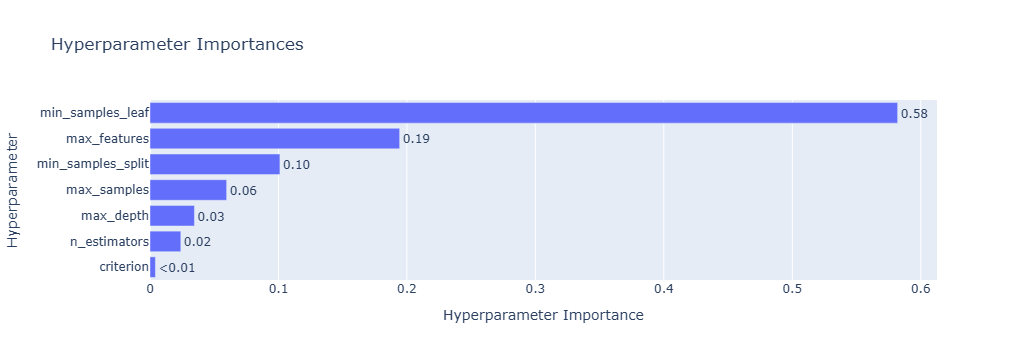

In [ ]:
# Plot
optuna.visualization.plot_param_importances(study)

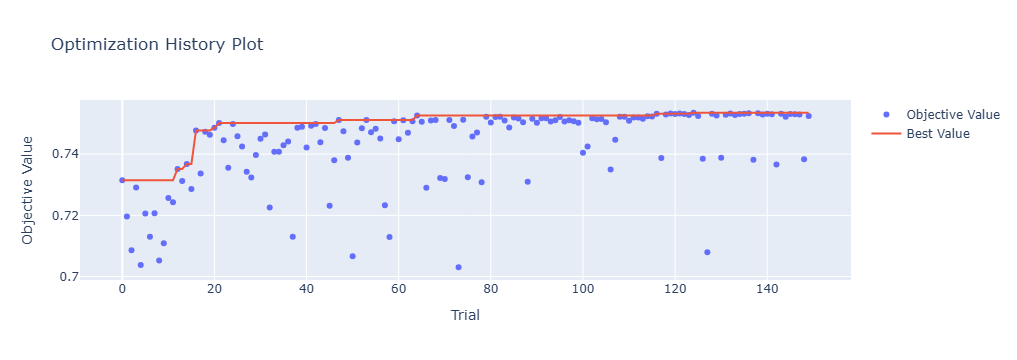

In [ ]:
optuna.visualization.plot_optimization_history(study)

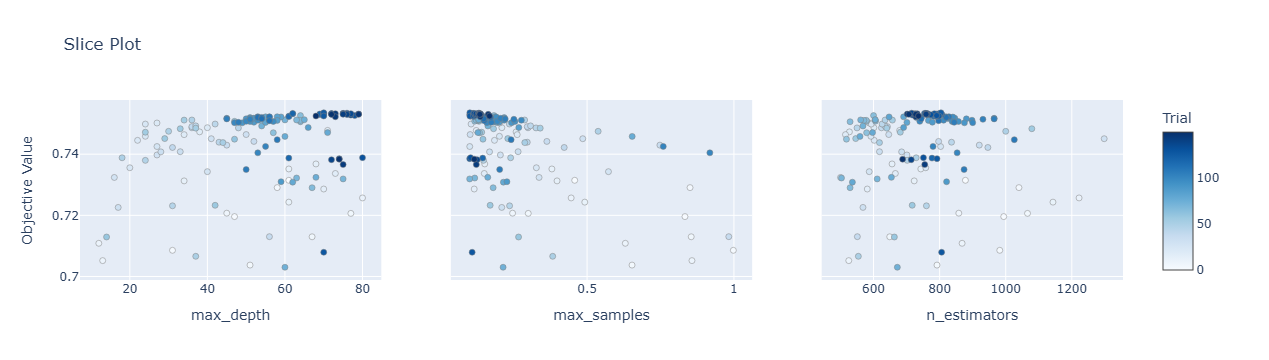

In [ ]:
optuna.visualization.plot_slice(study, params=['n_estimators', 'max_depth', 'max_samples'])

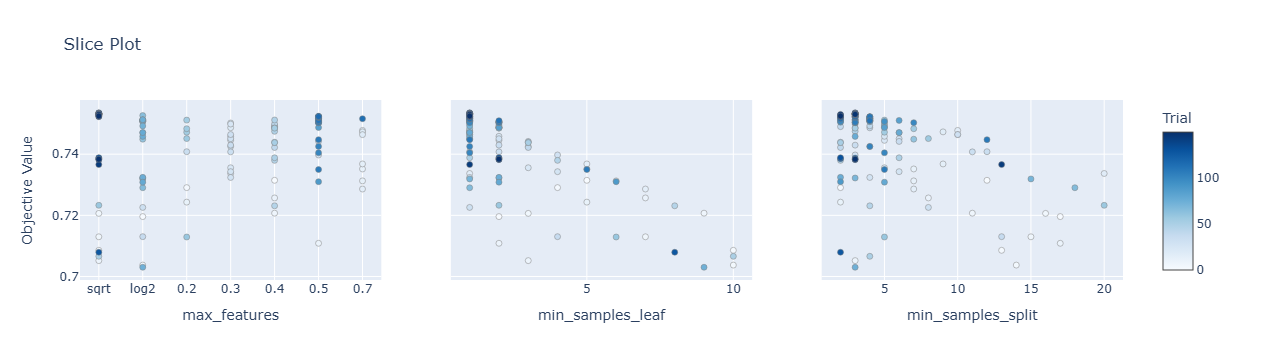

In [ ]:
optuna.visualization.plot_slice(study, params=['min_samples_split', 'min_samples_leaf', 'max_features'])

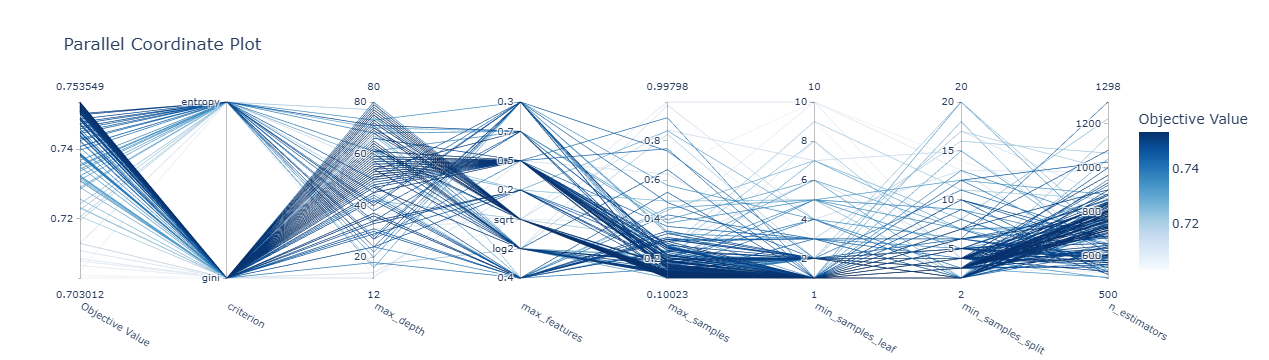

In [ ]:
optuna.visualization.plot_parallel_coordinate(study)

##### Evaluation

In [ ]:
# Evaluate the model with the tuned hyperparameters

pipeline_rfc = Pipeline([
    ('preprocessing', ct1),
    ('rfc', RandomForestClassifier(
        n_estimators=804,
        max_depth=70,
        max_features='sqrt',
        min_samples_leaf=1,
        min_samples_split=3,
        max_samples=0.1,
        criterion='gini',
        n_jobs=-1,
        class_weight='balanced'
    ))
])

pipeline_rfc.fit(X_train, y_train)

y_pred_train_rfc = pipeline_rfc.predict(X_train)
y_pred_valid_rfc = pipeline_rfc.predict(X_validation)

micro_f1_train_rfc = f1_score(y_train, y_pred_train_rfc, average='micro')
micro_f1_valid_rfc = f1_score(y_validation, y_pred_valid_rfc, average='micro')

print('Micro-averaged F1 (train):', micro_f1_train_rfc)
print('Micro-averaged F1 (validation):', micro_f1_valid_rfc)

confusion_matrix_rfc = confusion_matrix(y_validation, y_pred_valid_rfc)

print('\nConfusion Matrix:\n', confusion_matrix_rfc)
print('\nClassification Report:\n', classification_report(y_validation, y_pred_valid_rfc))

Micro-averaged F1 (train): 0.7916634689178819
Micro-averaged F1 (validation): 0.7581205272347039

Confusion Matrix:
 [[ 2944  1999    82]
 [ 1287 24958  3407]
 [  119  5713 11612]]

Classification Report:
               precision    recall  f1-score   support

           1       0.68      0.59      0.63      5025
           2       0.76      0.84      0.80     29652
           3       0.77      0.67      0.71     17444

    accuracy                           0.76     52121
   macro avg       0.74      0.70      0.71     52121
weighted avg       0.76      0.76      0.76     52121



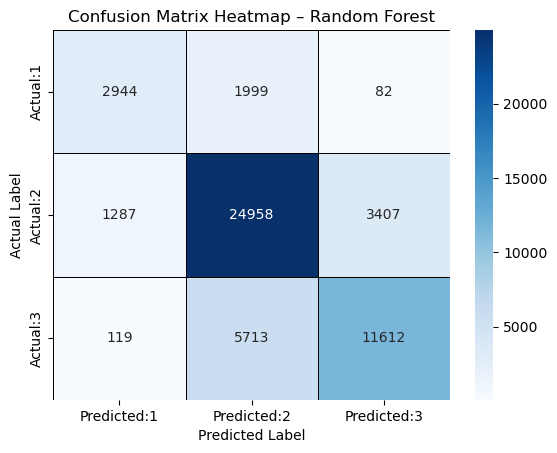

In [ ]:
# Confusion Matrix Heatmap

confusion_matrix_df_rfc = pd.DataFrame(
    data=confusion_matrix_rfc,
    columns=['Predicted:1', 'Predicted:2', 'Predicted:3'],
    index=['Actual:1', 'Actual:2', 'Actual:3']
)
                                                                            
sns.heatmap(confusion_matrix_df_rfc, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix Heatmap – Random Forest')
plt.show()

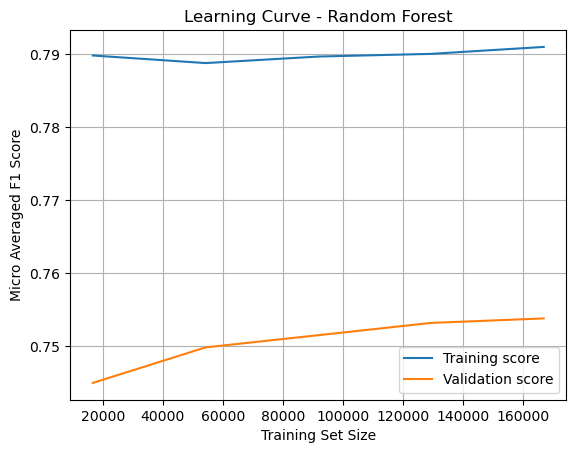

In [ ]:
# Get learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    pipeline_rfc,
    X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=5,
    scoring='f1_micro',
    n_jobs=8
)

# Plot learning curve
plt.plot(train_sizes, train_scores.mean(axis=1), label='Training score')
plt.plot(train_sizes, test_scores.mean(axis=1), label='Validation score')
plt.title('Learning Curve - Random Forest')
plt.xlabel('Training Set Size')
plt.ylabel('Micro-Averaged F1 Score')
plt.legend()
plt.grid()
plt.show()

- Micro-averaged F1 (validation): 0.7581, higher than that of LinearSVC.
- The model performed best on class 2, and worst on class 1.
- Class 1 and 3 were frequently misclassified as class 2.
- The learning curve indicates good learning and a mild overfitting trend.

##### Feature Importances

In [ ]:
# Get the columns' names of data after being preprocessed

pipeline_preprocessing = Pipeline([('preprocessing', clone(ct1).set_output(transform='pandas'))])
X_train_processed = pipeline_preprocessing.fit_transform(X_train)
feature_names = X_train_processed.columns
print(feature_names)

Index(['one-hot__geo_level_1_id_1', 'one-hot__geo_level_1_id_3',
       'one-hot__geo_level_1_id_4', 'one-hot__geo_level_1_id_5',
       'one-hot__geo_level_1_id_6', 'one-hot__geo_level_1_id_7',
       'one-hot__geo_level_1_id_8', 'one-hot__geo_level_1_id_9',
       'one-hot__geo_level_1_id_10', 'one-hot__geo_level_1_id_11',
       'one-hot__geo_level_1_id_12', 'one-hot__geo_level_1_id_13',
       'one-hot__geo_level_1_id_15', 'one-hot__geo_level_1_id_16',
       'one-hot__geo_level_1_id_17', 'one-hot__geo_level_1_id_18',
       'one-hot__geo_level_1_id_20', 'one-hot__geo_level_1_id_21',
       'one-hot__geo_level_1_id_22', 'one-hot__geo_level_1_id_25',
       'one-hot__geo_level_1_id_26', 'one-hot__geo_level_1_id_27',
       'one-hot__geo_level_1_id_30', 'one-hot__geo_level_1_id_31',
       'one-hot__land_surface_condition_o',
       'one-hot__land_surface_condition_t', 'one-hot__foundation_type_i',
       'one-hot__foundation_type_r', 'one-hot__foundation_type_u',
       'one-hot__fo

In [ ]:
# Get feature importances scores

feature_importances_rfc = pipeline_rfc.named_steps['rfc'].feature_importances_

importance_df_rfc = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importances_rfc
}).sort_values('importance', ascending=False)

importance_df_rfc

,feature,importance
63,remainder__id_3_03,0.217354
62,remainder__id_3_02,0.183791
49,num cols manipulation__height_area_ratio,0.075325
47,num cols manipulation__age,0.070121
27,one-hot__foundation_type_r,0.038930
...,...,...
61,remainder__has_secondary_use_other,0.001098
32,one-hot__ground_floor_type_other,0.001073
41,one-hot__plan_configuration_other,0.001062
38,one-hot__position_o,0.000865


<function matplotlib.pyplot.show(close=None, block=None)>

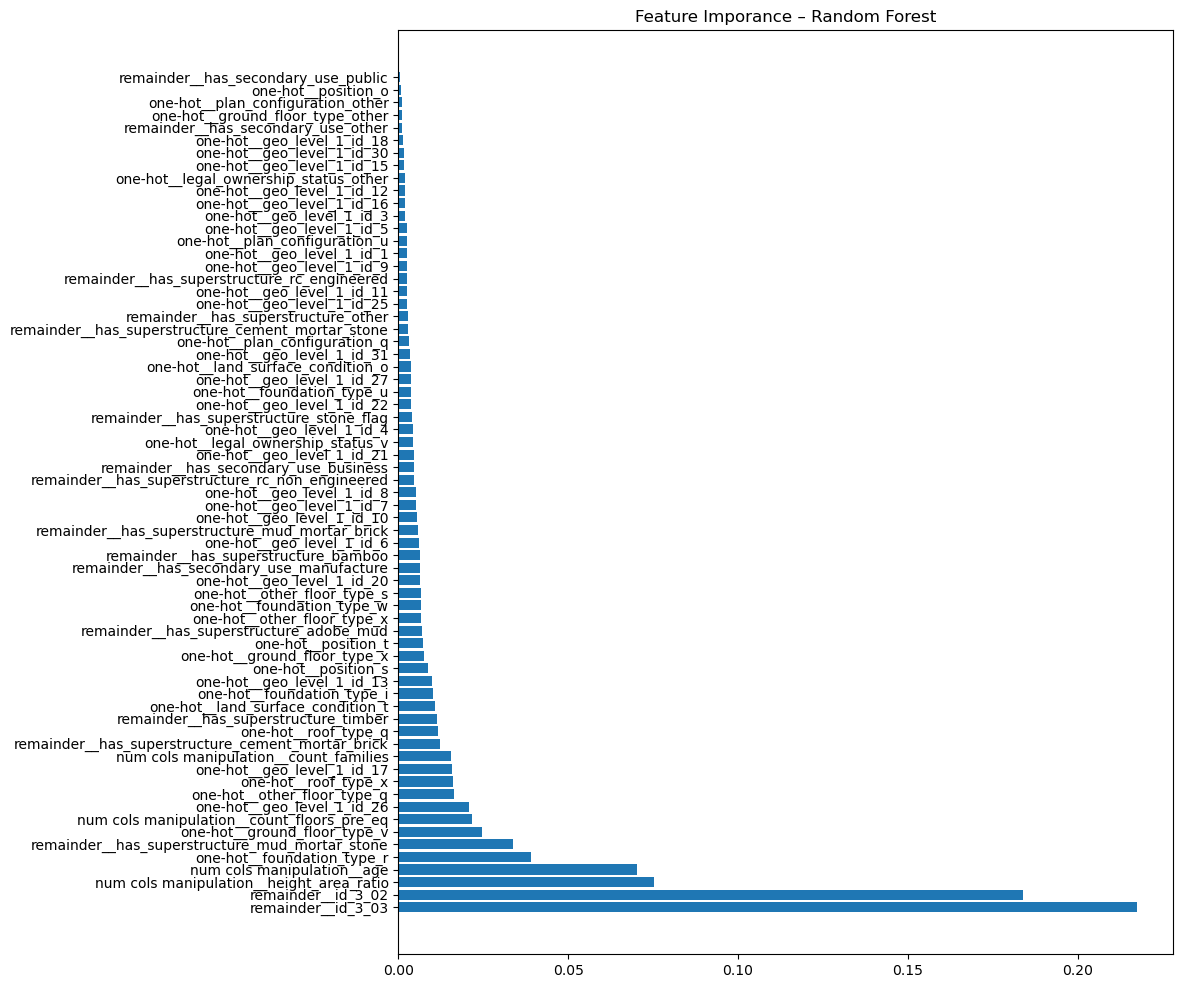

In [ ]:
# Plot feature imporance

plt.figure(figsize=(10, 12))
plt.barh(importance_df_rfc['feature'], importance_df_rfc['importance'])
plt.title('Feature Imporance – Random Forest')
plt.show

##### Prediction

In [ ]:
# Make predictions on the test set

test_predict_rfc = pipeline_rfc.predict(test_value1)
test_predict_rfc

array([3, 2, 2, ..., 2, 2, 2], dtype=int64)

In [ ]:
my_submission_rfc = pd.DataFrame(data=test_predict_rfc,
                             columns=submission_format.columns,
                             index=submission_format.index)

my_submission_rfc.head()

,damage_grade
building_id,
300051,3
99355,2
890251,2
745817,1
421793,3


In [ ]:
# Save the predictions into a csv file

now = datetime.now().strftime('%Y%m%d_%H%M%S')
filename = f'submission_{now}.csv'
my_submission_rfc.reset_index().to_csv('submission/' + filename, index=False)

# Print confirmation
print(f"Submission file saved successfully as 'submission/{filename}'")

Submission file saved successfully as 'submission/submission_20250519_191442.csv'


Submission score: 0.7376

#### Random Forest + Ordinal Classifier

The implementation of `OrdinalClassifier` is adapted from [Ordinal Classification (tune_sklearn, skorch)](https://www.kaggle.com/code/jayahn0104/ordinal-classification-tune-sklearn-skorch#2.-Model-Selection).

This method solves the three-class ordinal classification problem using the following steps：
1. Identify the three target classes (1, 2, 3) and fit two binary classifiers (`fit()`):
  - `clf1`: predicts whether $y > 1$
  - `clf2`: predicts whether $y > 2$

2. Calculate the probabilities of the three target classes for each instance (`predict_proba()`):
$$
Pr(y = 1) = 1 - Pr(y > 1)
$$

$$
Pr(y = 2) = Pr(y > 1) - Pr(y > 2)
$$

$$
Pr(y = 3) = Pr(y > 2) \\
$$

3. Select the target class with the highest probability as the final predicted value (`predict()`).

In [ ]:
# Adapted from https://www.kaggle.com/code/jayahn0104/ordinal-classification-tune-sklearn-skorch#2.-Model-Selection

class OrdinalClassifier(BaseEstimator):

    def __init__(self, clf):
        self.clf = clf
        self.clfs = {}

    def fit(self, X, y):
        self.unique_class = np.sort(np.unique(y))  # Get target unique values
        if self.unique_class.shape[0] > 2:
            for i in range(self.unique_class.shape[0]-1):
                # For each k - 1 ordinal value we fit a binary classification problem
                binary_y = (y > self.unique_class[i]).astype(np.uint8)
                clf = clone(self.clf)
                try:
                  clf.module
                except: # For others
                  clf.fit(X, binary_y)
                else: # For MLP
                  binary_y_reshape = binary_y.astype('float32').reshape(-1,1)
                  clf.fit(X, binary_y_reshape)
                self.clfs[i] = clf

    def predict_proba(self, X):
        clfs_predict = {k: self.clfs[k].predict_proba(X) for k in self.clfs}
        predicted = []
        for i, y in enumerate(self.unique_class):
            if i == 0:
                # V1 = 1 - Pr(y > V1)
                predicted.append(1 - clfs_predict[i][:,1])
            elif i in clfs_predict:
                # Vi = Pr(y > Vi-1) - Pr(y > Vi)
                 predicted.append(clfs_predict[i-1][:,1] - clfs_predict[i][:,1])
            else:
                # Vk = Pr(y > Vk-1)
                predicted.append(clfs_predict[i-1][:,1])
        try:
          self.clf.module
        except: # For others
          pred_proba = np.vstack(predicted).T      
        else: # For MLP
          pred_proba = np.hstack((predicted))
        
        return pred_proba

    def predict(self, X):
        idx =  np.argmax(self.predict_proba(X), axis=1)
        return self.unique_class[idx]  # Instead of returning the index, return the original y value

    def score(self, X, y, sample_weight=None):
        _, indexed_y = np.unique(y, return_inverse=True)
        return accuracy_score(indexed_y, self.predict(X), sample_weight=sample_weight)

##### Hyperparameter Tuning

In [ ]:
# Grid Search

pipeline_orfc = Pipeline([
    ('preprocessing', ct1),
    ('smotetomek', SMOTETomek(random_state=42)),
    ('orfc', OrdinalClassifier(RandomForestClassifier(class_weight='balanced')))
])

grid_orfc = {
    'smotetomek': [SMOTETomek(random_state=42), 'passthrough']
}

gcv_orfc = GridSearchCV(
    pipeline_orfc, 
    grid_orfc,
    scoring='f1_micro',
    cv=5,
    n_jobs=-1,
    verbose=2
)

# start time
start_time = time.time()

gcv_orfc.fit(X_train,y_train)

# calculate training time
training_time = (time.time() - start_time) / 60

print('Best Params:', gcv_orfc.best_params_)
print('Best Score:', gcv_orfc.best_score_)

# print training time
print(f'\nTraining Time: {training_time:.2f} min')

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best Params: {'smotetomek': 'passthrough'}
Best Score: 0.7359267075978512

Training Time: 11.69 min


In [ ]:
# Bayesian Optimisation

def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 600, 1100)
    max_depth = trial.suggest_int('max_depth', 30, 80)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.2, 0.3, 0.4, 0.5])
    criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
    max_samples = trial.suggest_float('max_samples', 0.1, 0.6)

    # Pipeline
    pipeline_orfc = Pipeline([
        ('preprocessing', ct1),
        ('orfc', OrdinalClassifier(RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            criterion=criterion,
            max_samples=max_samples,
            class_weight='balanced',
            n_jobs=3
        )))
    ])

    f1_score = cross_val_score(pipeline_orfc, X_train, y_train, cv=3, scoring='f1_micro', n_jobs=3).mean()
    return f1_score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

best_trial_orfc = study.best_trial

best_score_orfc = best_trial_orfc.value
best_params_orfc = best_trial_orfc.params

# Print the best params and the score
print('Best Score:', best_score_orfc)
print('Best Params:', best_params_orfc)

[I 2025-05-19 19:30:14,835] A new study created in memory with name: no-name-7ad84cd9-f7ab-4b9b-9f3d-f3a09f31868c
[I 2025-05-19 19:34:33,905] Trial 0 finished with value: 0.7030554471786893 and parameters: {'n_estimators': 1096, 'max_depth': 68, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 0.4, 'criterion': 'entropy', 'max_samples': 0.46430925187117233}. Best is trial 0 with value: 0.7030554471786893.
[I 2025-05-19 19:36:10,535] Trial 1 finished with value: 0.658955297572983 and parameters: {'n_estimators': 848, 'max_depth': 49, 'min_samples_split': 9, 'min_samples_leaf': 8, 'max_features': 'log2', 'criterion': 'entropy', 'max_samples': 0.5388363106037645}. Best is trial 0 with value: 0.7030554471786893.
[I 2025-05-19 19:36:48,238] Trial 2 finished with value: 0.7101736358820752 and parameters: {'n_estimators': 602, 'max_depth': 73, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'criterion': 'gini', 'max_samples': 0.2267166857087202}. Best is t

Best Score: 0.7536598137407662
Best Params: {'n_estimators': 1048, 'max_depth': 79, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.3, 'criterion': 'entropy', 'max_samples': 0.15462181860583274}


In [ ]:
best_score_orfc

0.7536598137407662

In [ ]:
best_params_orfc

{'n_estimators': 1048,
 'max_depth': 79,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 0.3,
 'criterion': 'entropy',
 'max_samples': 0.15462181860583274}

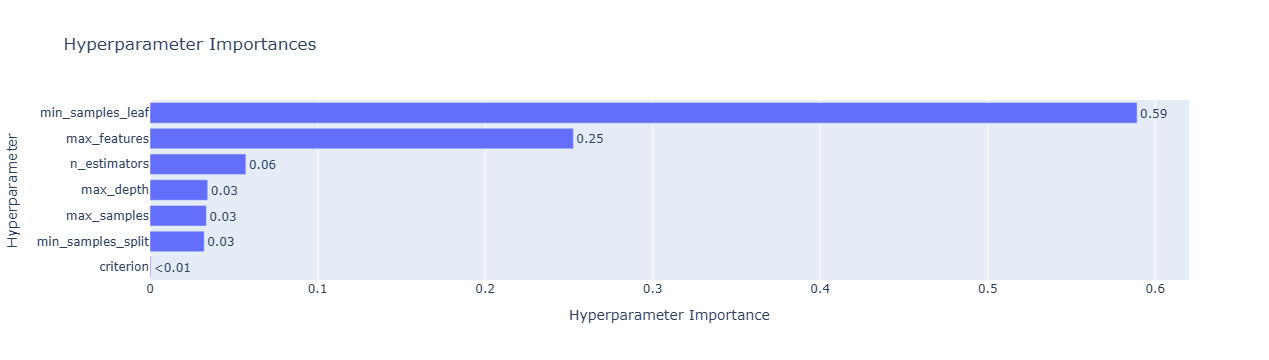

In [ ]:
optuna.visualization.plot_param_importances(study)

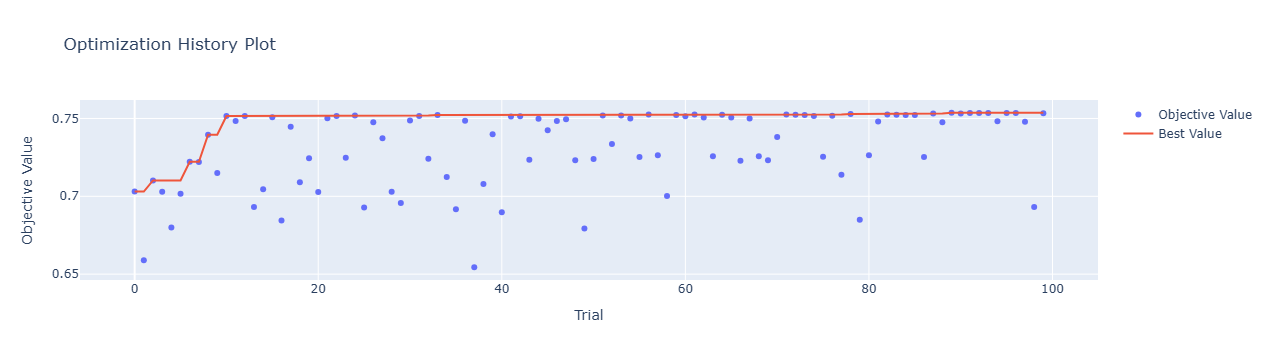

In [ ]:
optuna.visualization.plot_optimization_history(study)

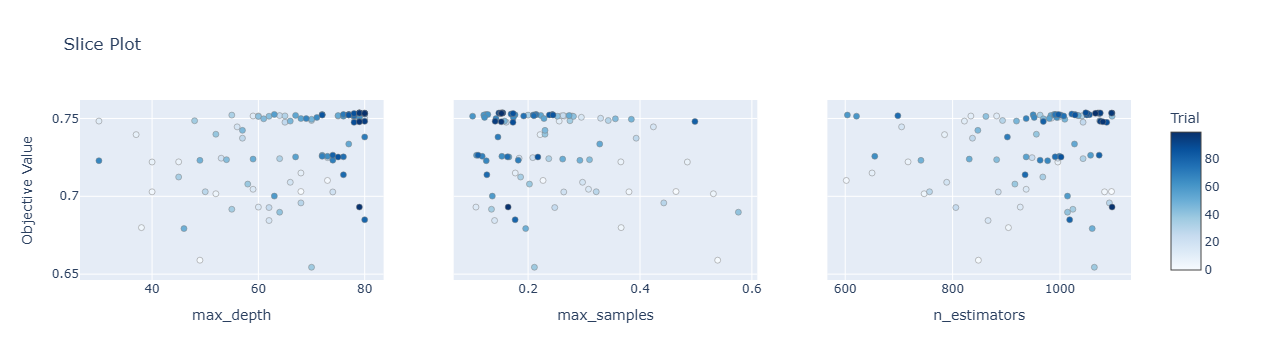

In [ ]:
optuna.visualization.plot_slice(study, params=['n_estimators', 'max_depth', 'max_samples'])

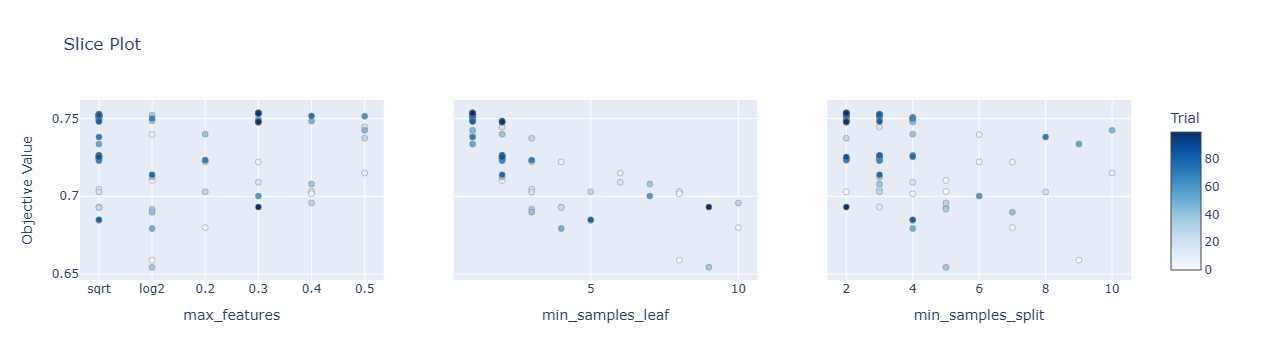

In [ ]:
optuna.visualization.plot_slice(study, params=['min_samples_split', 'min_samples_leaf', 'max_features'])

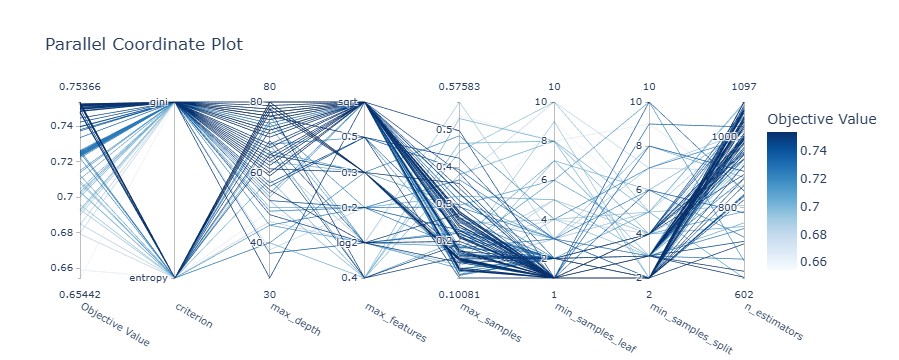

In [ ]:
optuna.visualization.plot_parallel_coordinate(study)

##### Evaluation

In [ ]:
# Evaluate the model with the tuned hyperparameters

pipeline_orfc = Pipeline([
    ('preprocessing', ct1),
    ('orfc', OrdinalClassifier(RandomForestClassifier(
        n_estimators=1048,
        max_depth=79,
        max_features=0.3,
        min_samples_split=2,
        min_samples_leaf=1,
        max_samples=0.1546,
        criterion='entropy',
        n_jobs=-1,
        class_weight='balanced'
    )))
])

pipeline_orfc.fit(X_train, y_train)

y_pred_train_orfc = pipeline_orfc.predict(X_train)
y_pred_valid_orfc = pipeline_orfc.predict(X_validation)

micro_f1_train_orfc = f1_score(y_train, y_pred_train_orfc, average='micro')
micro_f1_valid_orfc = f1_score(y_validation, y_pred_valid_orfc, average='micro')

print('Micro-averaged F1 (train):', micro_f1_train_orfc)
print('Micro-averaged F1 (validation):', micro_f1_valid_orfc)

confusion_matrix_orfc = confusion_matrix(y_validation, y_pred_valid_orfc)

print('\nConfusion Matrix:\n', confusion_matrix_orfc)
print('\nClassification Report:\n', classification_report(y_validation, y_pred_valid_orfc))

C:\Users\mrwho\anaconda3\Lib\site-packages\imblearn\pipeline.py:65: FutureWarning:

This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 0.15 instead of the current warning.



Micro-averaged F1 (train): 0.8215128549501152
Micro-averaged F1 (validation): 0.758178085608488

Confusion Matrix:
 [[ 2716  2213    96]
 [ 1028 25359  3265]
 [   99  5903 11442]]

Classification Report:
               precision    recall  f1-score   support

           1       0.71      0.54      0.61      5025
           2       0.76      0.86      0.80     29652
           3       0.77      0.66      0.71     17444

    accuracy                           0.76     52121
   macro avg       0.75      0.68      0.71     52121
weighted avg       0.76      0.76      0.75     52121



C:\Users\mrwho\anaconda3\Lib\site-packages\imblearn\pipeline.py:65: FutureWarning:

This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 0.15 instead of the current warning.



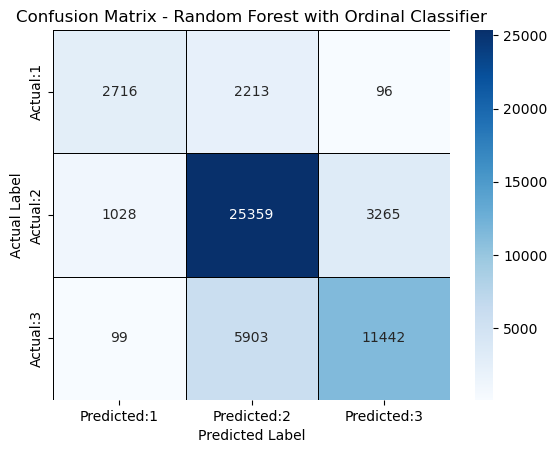

In [ ]:
# Confusion Matrix Heatmap

confusion_matrix_df_orfc = pd.DataFrame(
    data=confusion_matrix_orfc,
    columns=['Predicted:1', 'Predicted:2', 'Predicted:3'],
    index=['Actual:1', 'Actual:2', 'Actual:3']
)

sns.heatmap(confusion_matrix_df_orfc, annot=True, fmt='d', cmap='Blues', linewidths=0.5, linecolor='black')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Random Forest with Ordinal Classifier')
plt.show()

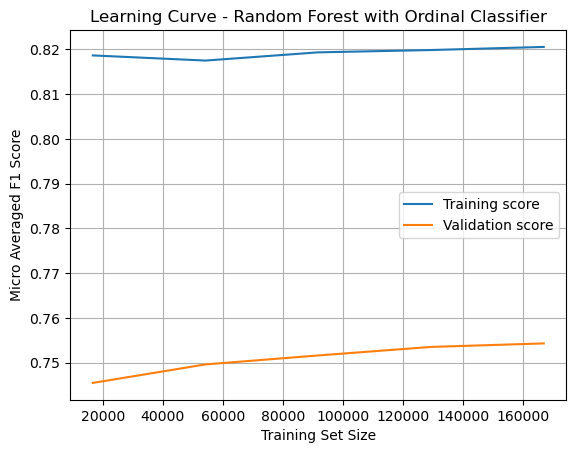

In [ ]:
# Get learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    pipeline_orfc,
    X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=5,
    scoring='f1_micro', 
    n_jobs=8
)

# Plot
plt.plot(train_sizes, train_scores.mean(axis=1), label='Training score')
plt.plot(train_sizes, test_scores.mean(axis=1), label='Validation score')
plt.title("Learning Curve - Random Forest with Ordinal Classifier")
plt.xlabel("Training Set Size")
plt.ylabel("Micro-Averaged F1 Score")
plt.legend()
plt.grid()
plt.show()

- Micro-averaged F1 (validation): 0.7582, almost identical to that of the standard Random Forest Model.

##### Prediction

In [ ]:
# Make predictions on the test set

test_predict_orfc = pipeline_orfc.predict(test_value1)
test_predict_orfc

C:\Users\mrwho\anaconda3\Lib\site-packages\imblearn\pipeline.py:65: FutureWarning:

This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 0.15 instead of the current warning.



array([3, 2, 2, ..., 2, 2, 2], dtype=int64)

In [ ]:
my_submission_orfc = pd.DataFrame(data=test_predict_orfc,
                             columns=submission_format.columns,
                             index=submission_format.index)

my_submission_orfc.head()

,damage_grade
building_id,
300051,3
99355,2
890251,2
745817,1
421793,3


In [ ]:
# Save the predictions into a csv file

now = datetime.now().strftime('%Y%m%d_%H%M%S')
filename = f'submission_{now}.csv'
my_submission_orfc.reset_index().to_csv('submission/' + filename, index=False)

# Print confirmation
print(f"Submission file saved successfully as 'submission/{filename}'")

Submission file saved successfully as 'submission/submission_20250519_225241.csv'


Submission score: 0.7394

## Summary

**Final Results**  
The fine-tuned Random Forest model with an ordinal classifier achieved the best micro-averaged F1 score of 0.7394, making an improvement of 0.1579 over the baseline. The highest ranking on the leaderboard was #1056.

**Feature Importance**  
The features that have the most importance are `geo_id_level_3`, `height_area_ratio`, `age` and `foundation_type`.

**Improvements and Future Work**  
- The final model shows slight overfitting. Future work could explore more effective hyperparameter configurations.
- `SMOTETomek()` was excluded during the grid search phase, as it potentially introduces noise while addressing class imbalance. Future work could explore alternative methods to better address class imbalance.
- Advanced modelling approaches, such as stacked classifiers could also be applied in the future.